# BƯỚC 6 & 7: ĐÁNH GIÁ NÂNG CAO, OPENCV, MINI-BATCH, HỆ MÀU VÀ SUY LUẬN

Kiểm định chéo giữa `Scikit-Learn` và `OpenCV cv2.kmeans` (Hungarian Label Alignment + thời gian thực thi), đo đánh đổi tốc độ/chất lượng `MiniBatchKMeans` kèm ảnh trực quan, so sánh không gian màu `RGB` vs `HSV` vs `CIE LAB`, tính `Silhouette Score` và thử nghiệm suy luận sang ảnh mới (`image-sea.png`).

> **Lưu ý:** Toàn bộ kết quả và file mô hình thử nghiệm tạm thời chỉ xử lý trong phạm vi notebook (`tempfile.TemporaryDirectory()`), hoàn toàn không ghi đè vào `results/` của `main.py`.

### 1. Nạp module và chuẩn bị dữ liệu chuẩn

In [1]:
import io
import sys
import tempfile
import time
from pathlib import Path

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from sklearn.cluster import MiniBatchKMeans

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import DEFAULT_IMAGE_PATH, FIGURE_DPI, FINAL_K, MAX_ITER, N_INIT, RANDOM_SEED, RAW_DATA_DIR, TARGET_SIZE
from src.data.loader import load_image
from src.data.preprocessing import convert_centroids_to_rgb, convert_color_space, flatten_pixels, resize_image
from src.deployment.predictor import ImageSegmentationPredictor
from src.evaluation.metrics import compute_silhouette
from src.models.kmeans_opencv import OpenCVKMeansTrainer
from src.models.kmeans_sklearn import SklearnKMeansTrainer
from src.models.minibatch_kmeans import MiniBatchKMeansTrainer
from src.models.persistence import save_model_pipeline
from src.segmentation.segmenter import ImageSegmenter

def show_figure(fig):
    """Hiển thị trực tiếp đối tượng matplotlib Figure dưới dạng PNG ngay trong notebook."""
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=FIGURE_DPI, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buf.getvalue()))

img_rgb, metadata = load_image(DEFAULT_IMAGE_PATH)
resized_rgb, resized_shape = resize_image(img_rgb, target_size=TARGET_SIZE)
pixel_matrix = flatten_pixels(resized_rgb, as_float=True)

sk_trainer = SklearnKMeansTrainer(random_state=RANDOM_SEED)
t0 = time.perf_counter()
final_model = sk_trainer.fit_final_model(pixel_matrix, optimal_k=FINAL_K, n_init=N_INIT, max_iter=MAX_ITER)
sk_time = max(time.perf_counter() - t0, 1e-6)
print(f"Đã huấn luyện xong mô hình chuẩn Scikit-Learn (K={FINAL_K}) trong {sk_time:.4f}s.")

Đã huấn luyện xong mô hình chuẩn Scikit-Learn (K=5) trong 0.7103s.


### 2. Kiểm định chéo với OpenCV `cv2.kmeans` (Hungarian Algorithm + Thời gian)

In [2]:
cv_trainer = OpenCVKMeansTrainer()
cv_compactness, cv_labels, _ = cv_trainer.train(pixel_matrix, k=FINAL_K, attempts=N_INIT, max_iter=MAX_ITER)
cv_report = cv_trainer.compare_with_sklearn(
    sklearn_labels=final_model.labels_,
    opencv_labels=cv_labels,
    sklearn_inertia=float(final_model.inertia_),
    opencv_compactness=cv_compactness,
    sklearn_time_sec=sk_time,
    opencv_time_sec=cv_trainer.last_fit_time_sec_,
)
display(pd.DataFrame([cv_report]))

,sklearn_inertia,opencv_compactness,inertia_relative_diff_pct,label_agreement_pct,ari,nmi,optimal_label_mapping,opencv_fit_time_sec,sklearn_fit_time_sec,opencv_vs_sklearn_speedup
0,121024704.0,1.210437e+08,0.0157,99.36,0.9834,0.9743,"{'0': 0, '1': 4, '2': 3, '3': 1, '4': 2}",0.2129,0.7103,3.34


### 3. Đánh đổi tốc độ / chất lượng với `MiniBatchKMeans` (Bảng & Trực quan hóa)

,model,batch_size,fit_time_sec,speedup,inertia,inertia_increase_pct,ari,nmi
0,Full KMeans,65536,0.4340,1.00,121024704.0,0.00,1.0000,1.0000
1,MiniBatch (b=256),256,0.9679,0.45,121054752.0,0.02,0.9938,0.9869
2,MiniBatch (b=512),512,0.7178,0.60,121602440.0,0.48,0.9300,0.9148
3,MiniBatch (b=1024),1024,0.6305,0.69,121342200.0,0.26,0.9100,0.9089
4,MiniBatch (b=2048),2048,0.1686,2.57,121410992.0,0.32,0.9085,0.9093
5,MiniBatch (b=4096),4096,0.1309,3.32,121542400.0,0.43,0.8821,0.8866


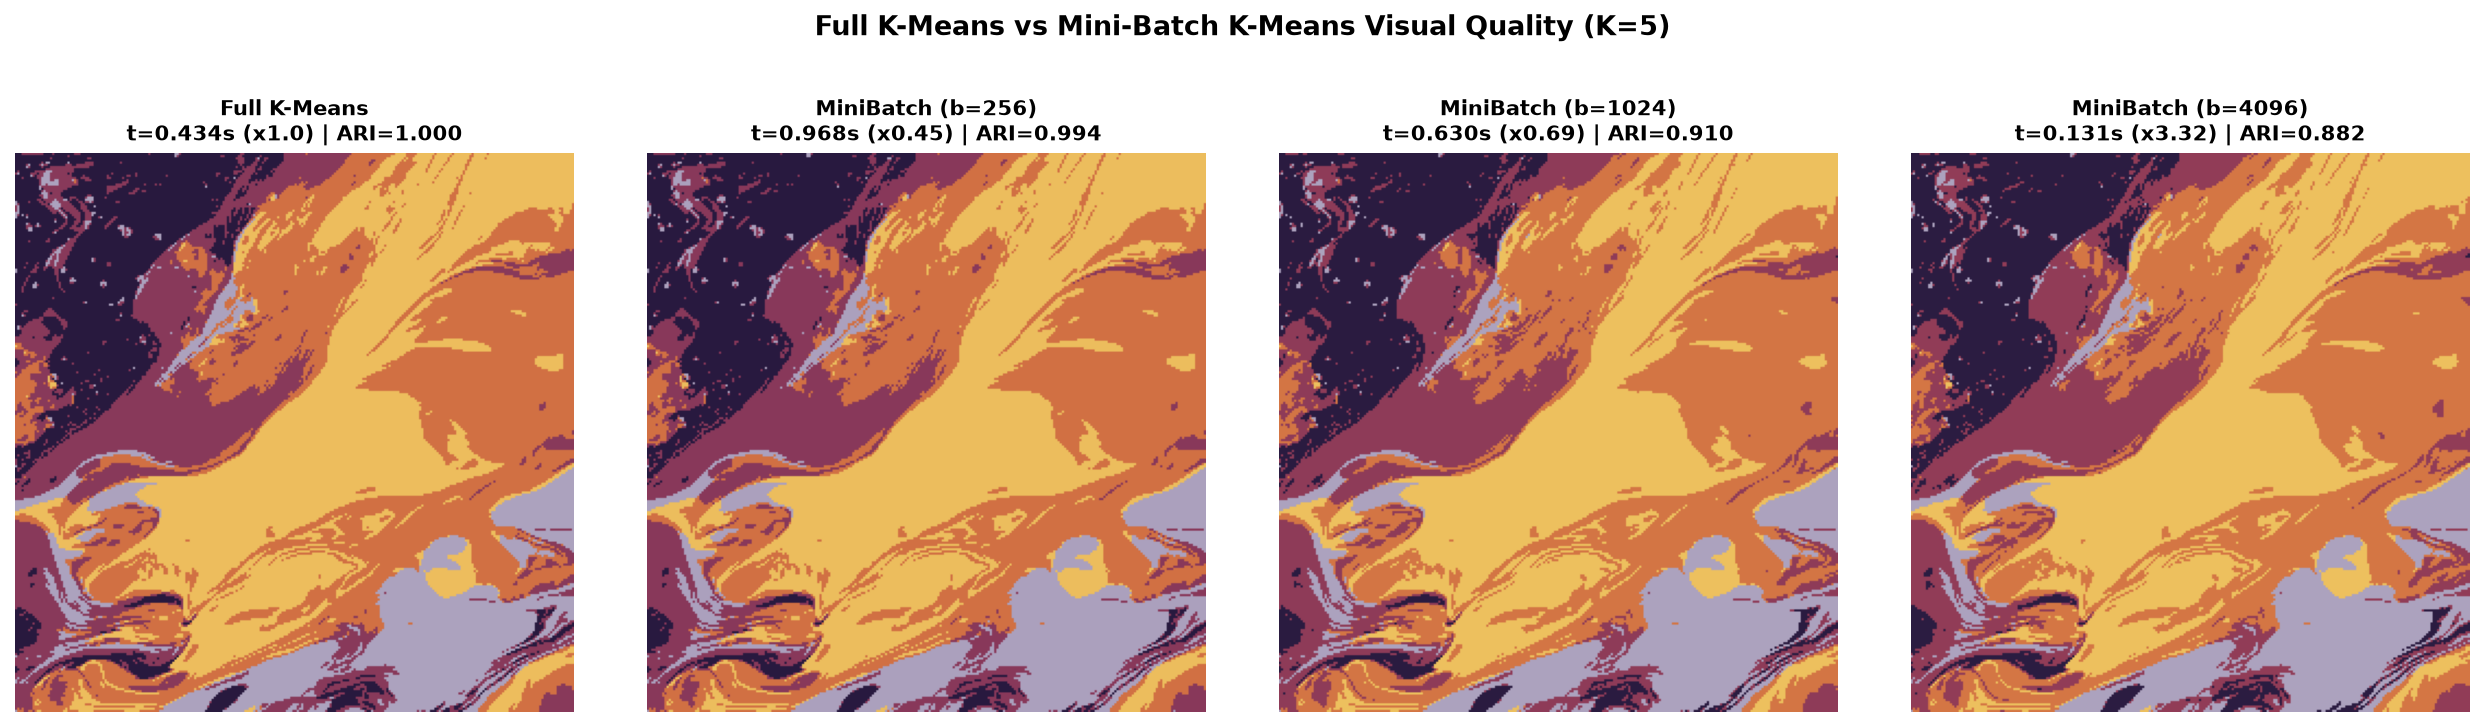

In [3]:
mb_trainer = MiniBatchKMeansTrainer(random_state=RANDOM_SEED)
df_mb = mb_trainer.compare_batch_sizes(
    pixel_matrix,
    k=FINAL_K,
    full_kmeans_model=final_model,
    batch_sizes=[256, 512, 1024, 2048, 4096],
)
display(df_mb)

segmenter = ImageSegmenter()
full_row = df_mb[df_mb['model'] == 'Full KMeans'].iloc[0]
mb_panels = [('Full K-Means', segmenter.reconstruct_segmented_image(final_model.labels_, final_model.cluster_centers_, resized_shape), full_row)]
for bs in (256, 1024, 4096):
    row = df_mb[df_mb['batch_size'] == bs].iloc[0]
    m_bs = MiniBatchKMeans(n_clusters=FINAL_K, batch_size=bs, n_init=N_INIT, max_iter=MAX_ITER, random_state=RANDOM_SEED)
    lbl_bs = m_bs.fit_predict(pixel_matrix)
    mb_panels.append((f'MiniBatch (b={bs})', segmenter.reconstruct_segmented_image(lbl_bs, m_bs.cluster_centers_, resized_shape), row))

fig_mb, axes_mb = plt.subplots(1, 4, figsize=(17, 4.9))
for ax, (name, img_vis, row) in zip(axes_mb, mb_panels):
    ax.imshow(img_vis)
    ax.set_title(f"{name}\nt={row['fit_time_sec']:.3f}s (x{row['speedup']}) | ARI={row['ari']:.3f}", fontsize=10, fontweight='bold')
    ax.axis('off')
fig_mb.suptitle(f'Full K-Means vs Mini-Batch K-Means Visual Quality (K={FINAL_K})', fontsize=13, fontweight='bold', y=0.98)
fig_mb.tight_layout(rect=[0.0, 0.0, 1.0, 0.89])
show_figure(fig_mb)

### 4. So sánh không gian màu (`RGB`, `HSV`, `CIE LAB`) & Suy luận thử nghiệm độc lập

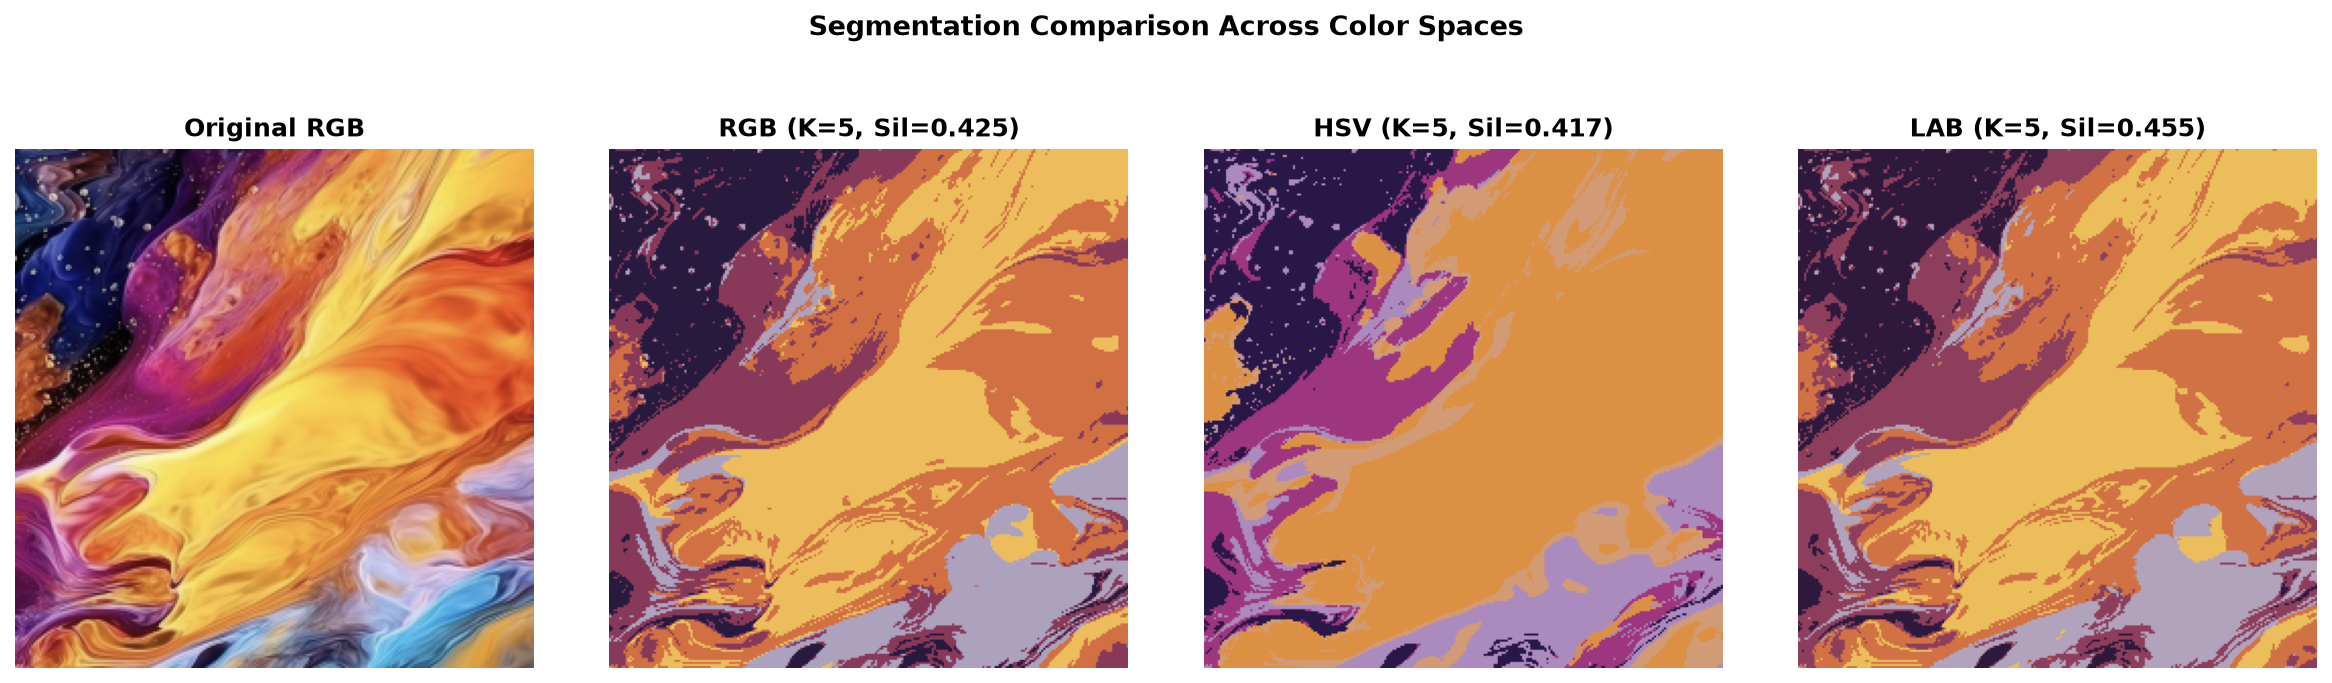

,Color Space,Silhouette,Fit Time (s)
0,RGB,0.4249,0.3470
1,HSV,0.4172,0.2695
2,LAB,0.4552,0.2615


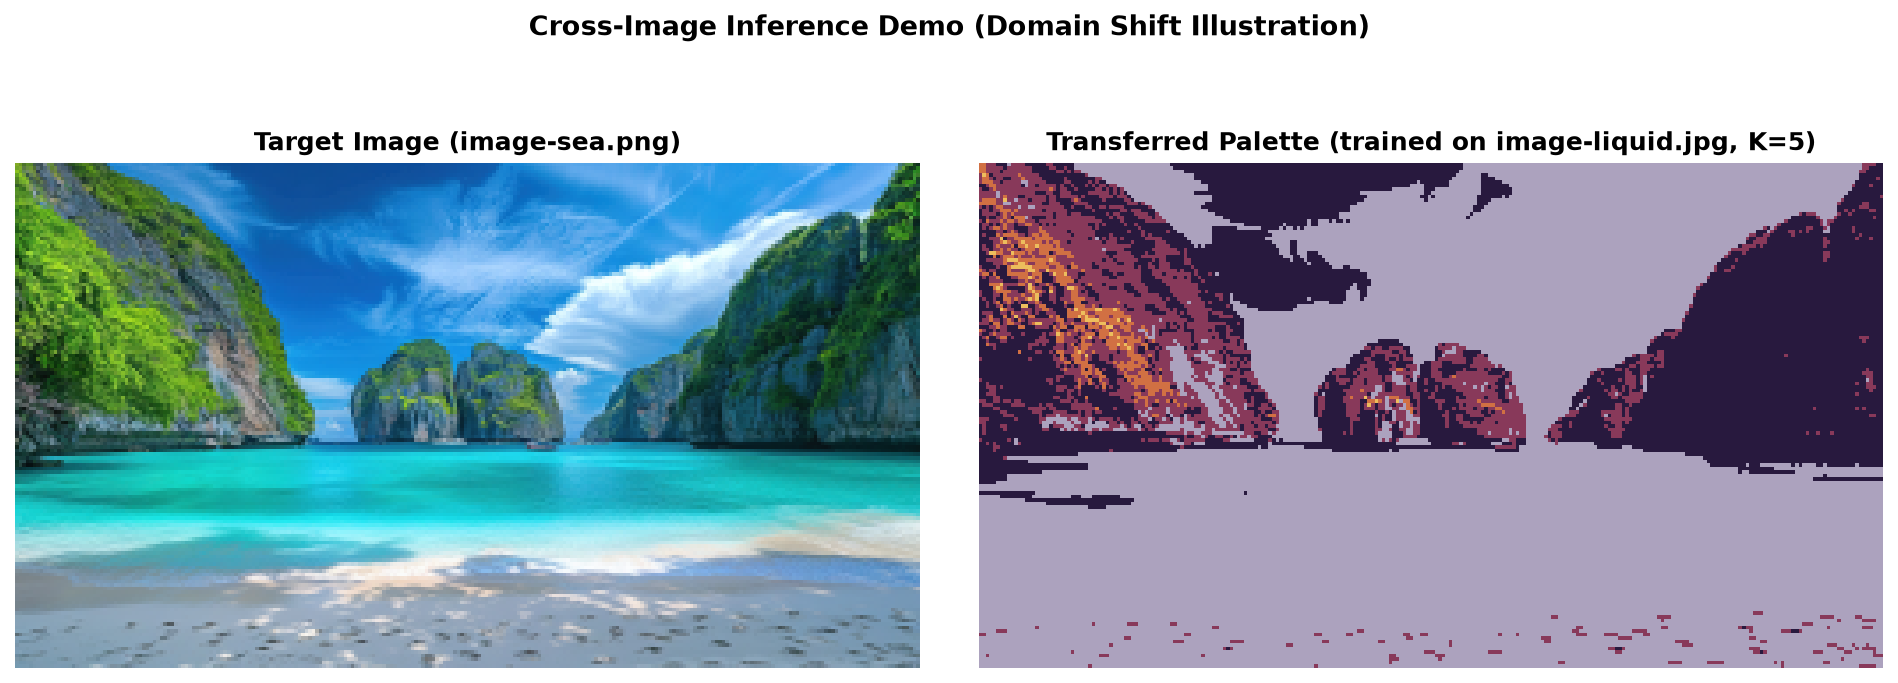

In [4]:
fig_cs, axes_cs = plt.subplots(1, 4, figsize=(16, 4.6))
axes_cs[0].imshow(resized_rgb)
axes_cs[0].set_title('Original RGB', fontweight='bold')
axes_cs[0].axis('off')

cs_rows = []
for idx, space in enumerate(['RGB', 'HSV', 'LAB'], start=1):
    space_img = resized_rgb if space == 'RGB' else convert_color_space(resized_rgb, 'RGB', space)
    space_px = flatten_pixels(space_img, as_float=True)
    t_s = time.perf_counter()
    m = sk_trainer.fit_final_model(space_px, optimal_k=FINAL_K, n_init=N_INIT, max_iter=MAX_ITER)
    fit_s = max(time.perf_counter() - t_s, 1e-6)
    sil = compute_silhouette(space_px, m.labels_, max_samples=5000, random_state=RANDOM_SEED)
    rgb_centers = convert_centroids_to_rgb(m.cluster_centers_, source_space=space)
    seg_vis = segmenter.reconstruct_segmented_image(m.labels_, rgb_centers, target_shape=resized_shape)
    axes_cs[idx].imshow(seg_vis)
    axes_cs[idx].set_title(f'{space} (K={FINAL_K}, Sil={sil:.3f})', fontweight='bold')
    axes_cs[idx].axis('off')
    cs_rows.append({'Color Space': space, 'Silhouette': round(sil, 4), 'Fit Time (s)': round(fit_s, 4)})

fig_cs.suptitle('Segmentation Comparison Across Color Spaces', fontsize=13, fontweight='bold', y=0.98)
fig_cs.tight_layout(rect=[0.0, 0.0, 1.0, 0.89])
show_figure(fig_cs)
display(pd.DataFrame(cs_rows))

# Suy luận thử nghiệm bằng thư mục tạm để không ghi đè dữ liệu của main.py
sea_img_path = RAW_DATA_DIR / 'image-sea.png'
if sea_img_path.exists():
    with tempfile.TemporaryDirectory() as tmp_dir:
        tmp_model = Path(tmp_dir) / 'temp_model.joblib'
        save_model_pipeline(final_model, tmp_model, metadata={'optimal_k': FINAL_K, 'color_space': 'RGB'})
        predictor = ImageSegmentationPredictor(model_path=tmp_model)
        pred = predictor.predict(sea_img_path, return_original_size=False, target_size=TARGET_SIZE)
        sea_rgb, _ = load_image(sea_img_path)
        sea_small, _ = resize_image(sea_rgb, target_size=TARGET_SIZE)
        fig_inf, ax_inf = plt.subplots(1, 2, figsize=(13, 4.6))
        ax_inf[0].imshow(sea_small)
        ax_inf[0].set_title(f'Target Image ({sea_img_path.name})', fontweight='bold')
        ax_inf[0].axis('off')
        ax_inf[1].imshow(pred['segmented_image'])
        ax_inf[1].set_title(f"Transferred Palette (trained on {metadata['file_name']}, K={FINAL_K})", fontweight='bold')
        ax_inf[1].axis('off')
        fig_inf.suptitle('Cross-Image Inference Demo (Domain Shift Illustration)', fontsize=13, fontweight='bold', y=0.98)
        fig_inf.tight_layout(rect=[0.0, 0.0, 1.0, 0.87])
        show_figure(fig_inf)